# 🏦 Real-Time Digital Banking Fraud Detection using a Mamdani Fuzzy Inference System

**Spec ID:** `SPEC-BARCLAYS-FRD-01` · **Method:** Specification-Driven Development (SDD) · **Target:** Barclays Retail & Digital Banking

This notebook is a complete, runnable implementation of the SDD blueprint:

| Section | What you get |
|---|---|
| 1–3 | Setup, the spec encoded as data (membership functions + rule base), the vectorised fuzzy engine |
| 4 | Visual proof of the linguistic variables and a first end-to-end transaction (JSON in → JSON out) |
| 5 | **Acceptance tests TC-01…TC-04** (spec-faithful engine vs. extended engine) |
| 6 | **Test-input library** – 20 named scenarios + edge cases to demo live |
| 7 | **Manual testing** – sliders, a type-your-own cell, and a paste-your-own-JSON cell |
| 8 | Explainability, risk-surface heatmaps, and rule-coverage analysis |
| 9 | Robustness (bad payloads, fuzzing) and performance (latency vs. 30 ms / 50 ms budgets) |
| 10 | NFR-02 false-positive simulation vs. a legacy binary engine |
| 11 | JSON audit export (FR-04 / NFR-03) and an auto-generated compliance scorecard |

**How to run:** `Runtime → Run all` (≈ 10–20 s total). Only NumPy / pandas / matplotlib are used – all pre-installed in Colab, no `pip install` needed.
**Running locally:** `pip install numpy pandas matplotlib ipywidgets jupyter`

In [1]:
# ===== SECTION 1 · SETUP =====
import json, time, uuid
from dataclasses import dataclass
from datetime import datetime, timezone
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:                      # plain-python fallback
    display = print

pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

print(f"numpy {np.__version__} | pandas {pd.__version__} | ready ✔")

numpy 2.1.3 | pandas 2.2.3 | ready ✔


## 2 · The specification, encoded as data

Everything below is transcribed **directly** from the SDD blueprint (§4 membership functions, §5 rule matrix, §6 decision bands).
Rules **R1–R6** are exactly as specified. Rules **R7–R10** are *clearly-labelled extensions* (`origin="extension"`) – see Section 5 for why they are needed (the 6-rule base leaves holes, including one that makes acceptance test **TC-04 impossible to pass**). They can be switched off with `FuzzyFraudEngine(extended=False)`.

In [2]:
# ===== SECTION 2 · SPEC AS DATA =====
def tri(a, b, c):            # triangular [a,b,c]  ->  trapezoid (a,b,b,c)
    return (a, b, b, c)

SPEC = {
    "project_id": "SPEC-BARCLAYS-FRD-01",
    "universe": {"velocity": (0, 10), "geo_distance": (0, 2000),
                 "device_anomaly": (0, 10), "fraud_risk": (0, 100)},
    "terms": {                                                   # spec §4.B / §4.C
        "velocity":       {"normal": tri(0, 0, 3), "elevated": tri(2, 5, 7), "frantic": (5, 8, 10, 10)},
        "geo_distance":   {"local": tri(0, 0, 50), "regional": tri(30, 250, 500), "international": (300, 800, 2000, 2000)},
        "device_anomaly": {"trusted": tri(0, 0, 3), "suspicious": tri(2, 5, 7), "malicious": (6, 8, 10, 10)},
        "fraud_risk":     {"low": tri(0, 0, 35), "medium": tri(30, 50, 70), "high": (65, 85, 100, 100)},
    },
    # spec §6 – (band, upper bound of score, decision, HTTP status, action code)
    "bands": [("LOW",    35.0,  "Allow Transaction",       200, "AUTHORIZED"),
              ("MEDIUM", 70.0,  "Step-Up Authentication",  202, "TRIGGER_OTP_CHALLENGE"),
              ("HIGH",   100.0, "Block & Alert",           403, "FREEZE_SESSION_NOTIFY_OPS")],
    "latency_budget_ms": {"end_to_end": 50.0, "inference": 30.0},   # FR-01 / NFR-01
}

ANY = None

@dataclass(frozen=True)
class Rule:
    rid: str
    velocity: Optional[str]
    geo: Optional[str]
    device: Optional[str]
    out: str
    op: str = "AND"            # R3 is the only OR rule in the spec
    origin: str = "spec"       # "spec" or "extension"

    def text(self):
        parts = [f"{n}={t}" for n, t in (("velocity", self.velocity), ("geo", self.geo), ("device", self.device)) if t]
        return f"IF {(' ' + self.op + ' ').join(parts)} THEN risk={self.out}"

RULES = [
    # ---- exactly as in the blueprint (§5) ----
    Rule("R1", "frantic",  "international", "malicious",  "high"),
    Rule("R2", "normal",   "local",         "trusted",    "low"),
    Rule("R3", "elevated", "regional",      ANY,          "medium", op="OR"),
    Rule("R4", "frantic",  ANY,             "suspicious", "high"),
    Rule("R5", "normal",   "international", "trusted",    "medium"),
    Rule("R6", "normal",   ANY,             "malicious",  "high"),
    # ---- proposed extensions: close coverage holes in the 6-rule base ----
    Rule("R7",  "elevated", ANY, "malicious",  "high",   origin="extension"),   # completes the R6 pattern
    Rule("R8",  "frantic",  ANY, "malicious",  "high",   origin="extension"),   # needed for TC-04
    Rule("R9",  "normal",   ANY, "suspicious", "medium", origin="extension"),   # odd device, calm velocity
    Rule("R10", "frantic",  ANY, "trusted",    "medium", origin="extension"),   # burst spending, trusted device
]

for r in RULES:
    print(f"{r.rid:>3} [{r.origin:9}] {r.text()}")

 R1 [spec     ] IF velocity=frantic AND geo=international AND device=malicious THEN risk=high
 R2 [spec     ] IF velocity=normal AND geo=local AND device=trusted THEN risk=low
 R3 [spec     ] IF velocity=elevated OR geo=regional THEN risk=medium
 R4 [spec     ] IF velocity=frantic AND device=suspicious THEN risk=high
 R5 [spec     ] IF velocity=normal AND geo=international AND device=trusted THEN risk=medium
 R6 [spec     ] IF velocity=normal AND device=malicious THEN risk=high
 R7 [extension] IF velocity=elevated AND device=malicious THEN risk=high
 R8 [extension] IF velocity=frantic AND device=malicious THEN risk=high
 R9 [extension] IF velocity=normal AND device=suspicious THEN risk=medium
R10 [extension] IF velocity=frantic AND device=trusted THEN risk=medium


## 3 · The fuzzy engine (Mamdani, pure NumPy)

**Pipeline:** fuzzify → rule strengths (`AND = min`, `OR = max`) → implication (clip output set) → aggregation (`max`) → **centroid** defuzzification → decision band.

* One vectorised code path serves both a single transaction and 100 000 of them.
* Scores are rounded to 1 decimal before banding, so the spec's ranges `[0,35.0] / [35.1,70.0] / [70.1,100]` are matched exactly.
* **Fail-safe:** if *no* rule fires, the score is fixed at 50 (→ Step-Up OTP) and the response is flagged `NO_RULE_FIRED_FALLBACK`. The spec is silent on this case; failing to *step-up* rather than *allow* is the safe choice for a bank.
* Invalid payloads are rejected with `400` (never silently authorised); out-of-range metrics are clamped and flagged.

In [3]:
# ===== SECTION 3 · ENGINE =====
VARS = ("velocity", "geo_distance", "device_anomaly")

def trapmf(x, a, b, c, d):
    """Trapezoidal membership. Triangles are passed as (a,b,b,c). Handles shoulders (a==b or c==d)."""
    x = np.asarray(x, dtype=float)
    left  = (x >= a).astype(float) if b == a else np.clip((x - a) / (b - a), 0.0, 1.0)
    right = (x <= d).astype(float) if c == d else np.clip((d - x) / (d - c), 0.0, 1.0)
    return np.minimum(left, right)

def decide(score):
    """Map a crisp score to (band, decision, http_status, action_code) using spec §6."""
    s = float(np.round(score, 1))
    for band, upper, decision, code, action in SPEC["bands"]:
        if s <= upper:
            return band, decision, code, action
    return SPEC["bands"][-1][0], SPEC["bands"][-1][2], SPEC["bands"][-1][3], SPEC["bands"][-1][4]

def batch_decisions(scores):
    s = np.round(np.asarray(scores, float), 1)
    return np.where(s <= 35.0, "Allow Transaction", np.where(s <= 70.0, "Step-Up Authentication", "Block & Alert"))

def _is_num(x):
    return isinstance(x, (int, float, np.integer, np.floating)) and not isinstance(x, bool)

def validate_payload(p):
    """Return (errors, warnings, [velocity, geo, device]) for the spec §4.A payload."""
    errors, warns, vals = [], [], []
    if not isinstance(p, dict):
        return ["payload must be a JSON object"], warns, None
    for k in ("transaction_id", "account_id"):
        if not isinstance(p.get(k), str) or not p[k].strip():
            errors.append(f"'{k}' must be a non-empty string")
    try:
        datetime.fromisoformat(str(p.get("timestamp")).replace("Z", "+00:00"))
    except Exception:
        errors.append("'timestamp' must be ISO-8601")
    amt = p.get("amount_gbp")
    if not _is_num(amt) or not np.isfinite(amt) or amt < 0:
        errors.append("'amount_gbp' must be a finite number >= 0")
    m = p.get("metrics")
    if not isinstance(m, dict):
        errors.append("'metrics' must be an object")
    else:
        for key, var in (("velocity_1h", "velocity"), ("geo_distance_km", "geo_distance"),
                         ("device_anomaly_score", "device_anomaly")):
            x = m.get(key)
            if not _is_num(x) or not np.isfinite(x):
                errors.append(f"metrics.{key} must be a finite number")
                continue
            lo, hi = SPEC["universe"][var]
            if key == "velocity_1h" and float(x) != int(x):
                warns.append("metrics.velocity_1h is fractional (spec says integer) - accepted")
            if x < lo or x > hi:
                warns.append(f"metrics.{key}={x} outside [{lo},{hi}] -> clamped")
                x = min(max(x, lo), hi)
            vals.append(float(x))
    if errors or len(vals) != 3:
        return errors, warns, None
    return errors, warns, vals


class FuzzyFraudEngine:
    def __init__(self, extended=True, resolution=1001, fallback_score=50.0):
        self.extended = extended
        self.rules = [r for r in RULES if extended or r.origin == "spec"]
        self.y = np.linspace(*SPEC["universe"]["fraud_risk"], resolution)
        self.curves = {t: trapmf(self.y, *p) for t, p in SPEC["terms"]["fraud_risk"].items()}
        self.fallback = float(fallback_score)
        self._out_idx = {t: [j for j, r in enumerate(self.rules) if r.out == t] for t in self.curves}

    # -- core (vectorised) ---------------------------------------------------
    def _infer_arrays(self, v, g, d, keep_curve=False):
        mu = {"velocity":       {t: trapmf(v, *p) for t, p in SPEC["terms"]["velocity"].items()},
              "geo_distance":   {t: trapmf(g, *p) for t, p in SPEC["terms"]["geo_distance"].items()},
              "device_anomaly": {t: trapmf(d, *p) for t, p in SPEC["terms"]["device_anomaly"].items()}}
        S = np.zeros((len(v), len(self.rules)))
        for j, r in enumerate(self.rules):
            parts = [mu[var][term] for var, term in zip(VARS, (r.velocity, r.geo, r.device)) if term is not None]
            S[:, j] = np.minimum.reduce(parts) if r.op == "AND" else np.maximum.reduce(parts)
        agg = np.zeros((len(v), len(self.y)))
        for term, idx in self._out_idx.items():
            if idx:
                s = S[:, idx].max(axis=1)
                np.maximum(agg, np.minimum(s[:, None], self.curves[term][None, :]), out=agg)
        area = agg.sum(axis=1)
        none = area < 1e-12
        score = np.where(none, self.fallback, (agg * self.y).sum(axis=1) / np.where(none, 1.0, area))
        return score, S, none, (agg if keep_curve else None), mu

    def infer_batch(self, velocity, geo_distance, device_anomaly, chunk=2000):
        """Score many transactions at once. Returns dict(score, no_rule, clipped, strengths)."""
        v, g, d = (np.atleast_1d(np.asarray(a, float)) for a in (velocity, geo_distance, device_anomaly))
        U = SPEC["universe"]
        clipped = ((v < U["velocity"][0]) | (v > U["velocity"][1]) | (g < U["geo_distance"][0]) |
                   (g > U["geo_distance"][1]) | (d < U["device_anomaly"][0]) | (d > U["device_anomaly"][1]))
        v, g, d = np.clip(v, *U["velocity"]), np.clip(g, *U["geo_distance"]), np.clip(d, *U["device_anomaly"])
        n = len(v)
        score, none = np.empty(n), np.empty(n, bool)
        S = np.empty((n, len(self.rules)))
        for i in range(0, n, chunk):
            sl = slice(i, i + chunk)
            score[sl], S[sl], none[sl], _, _ = self._infer_arrays(v[sl], g[sl], d[sl])
        return {"score": score, "no_rule": none, "clipped": clipped, "strengths": S}

    # -- API-style single-transaction evaluation -------------------------------
    def evaluate(self, payload, keep_curve=False):
        t0 = time.perf_counter()
        errors, warns, vals = validate_payload(payload)
        pl = payload if isinstance(payload, dict) else {}
        base = {"transaction_id": pl.get("transaction_id"), "account_id": pl.get("account_id"),
                "timestamp": pl.get("timestamp")}
        if errors:
            return {**base, "status_code": 400, "action": "REJECT_INVALID_PAYLOAD",
                    "decision": "Reject (invalid input)", "risk_score": None, "risk_band": None,
                    "errors": errors, "fired_rules": [], "flags": ["INVALID_PAYLOAD"],
                    "latency_ms": round((time.perf_counter() - t0) * 1000, 3)}
        v, g, d = (np.array([x]) for x in vals)
        t1 = time.perf_counter()
        score, S, none, agg, mu = self._infer_arrays(v, g, d, keep_curve)
        infer_ms = (time.perf_counter() - t1) * 1000
        score = float(score[0])
        band, decision, code, action = decide(score)

        fired = [{"rule_id": r.rid, "rule": r.text(), "strength": round(float(S[0, j]), 4),
                  "consequent": r.out, "origin": r.origin}
                 for j, r in enumerate(self.rules) if S[0, j] > 1e-9]
        fired.sort(key=lambda f: -f["strength"])
        flags = list(warns and ["INPUT_CLAMPED_OR_ADJUSTED"] or [])
        if bool(none[0]):
            flags.append("NO_RULE_FIRED_FALLBACK")
        ext = sorted({f["rule_id"] for f in fired if f["origin"] == "extension"})
        if ext:
            flags.append("EXTENSION_RULES_USED:" + ",".join(ext))
        if bool(none[0]):
            why = "No rule fired -> fail-safe step-up (score fixed at fallback)."
        else:
            why = f"Score {score:.1f} ({band}). Driven by " + ", ".join(
                f"{f['rule_id']} ({f['consequent']}, strength {f['strength']:.2f})" for f in fired[:3])
        resp = {**base, "status_code": code, "action": action, "decision": decision,
                "risk_score": round(score, 2), "risk_band": band,
                "inputs_used": {"velocity_1h": vals[0], "geo_distance_km": vals[1], "device_anomaly_score": vals[2]},
                "memberships": {var: {t: round(float(a[0]), 4) for t, a in terms.items() if a[0] > 1e-9}
                                for var, terms in mu.items()},
                "fired_rules": fired, "explanation": why, "flags": flags, "warnings": warns,
                "engine": {"rule_set": "extended" if self.extended else "spec-only", "defuzzification": "centroid",
                           "spec_id": SPEC["project_id"]},
                "inference_ms": round(infer_ms, 3),
                "latency_ms": round((time.perf_counter() - t0) * 1000, 3)}
        if keep_curve:
            resp["_curve"] = (self.y, agg[0])
        return resp


engine      = FuzzyFraudEngine(extended=True)    # spec rules + labelled extensions (default for the demo)
engine_spec = FuzzyFraudEngine(extended=False)   # exactly the 6 rules in the blueprint
print(f"engines ready  ->  extended: {len(engine.rules)} rules | spec-only: {len(engine_spec.rules)} rules")

engines ready  ->  extended: 10 rules | spec-only: 6 rules


In [4]:
# ===== SECTION 3b · HELPERS (payload builder, tables, plots) =====
ACTION_COLORS = {"Allow Transaction": "#d4edda", "Step-Up Authentication": "#fff3cd", "Block & Alert": "#f8d7da"}
BAND_COLORS = {"low": "#2e9e5b", "medium": "#f0a020", "high": "#d64545"}

def make_payload(velocity, geo_distance, device_anomaly, amount=100.0, account="ACC-DEMO", txid=None, ts=None):
    """Build a spec-compliant JSON payload (§4.A) from the three behavioural metrics."""
    return {"transaction_id": txid or f"TX-{uuid.uuid4().hex[:8].upper()}",
            "account_id": account,
            "timestamp": ts or datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "amount_gbp": float(amount),
            "metrics": {"velocity_1h": velocity, "geo_distance_km": geo_distance, "device_anomaly_score": device_anomaly}}

def clean(resp):
    """Drop private keys (e.g. the plotting curve) so a response can be printed / exported."""
    return {k: v for k, v in resp.items() if not k.startswith("_")}

def show(df, action_col="Action"):
    """Display a DataFrame with the action column colour-coded (falls back to plain display)."""
    try:
        f = lambda v: f"background-color: {ACTION_COLORS.get(v, '')}"
        st = df.style.map(f, subset=[action_col]) if hasattr(df.style, "map") else df.style.applymap(f, subset=[action_col])
        display(st)
    except Exception:
        display(df)

def plot_memberships():
    fig, axes = plt.subplots(2, 2, figsize=(13, 7))
    palettes = {"velocity": ["#2e9e5b", "#f0a020", "#d64545"], "geo_distance": ["#2e9e5b", "#f0a020", "#d64545"],
                "device_anomaly": ["#2e9e5b", "#f0a020", "#d64545"], "fraud_risk": ["#2e9e5b", "#f0a020", "#d64545"]}
    titles = {"velocity": "Transaction velocity (tx / hour)", "geo_distance": "Geographical distance (km)",
              "device_anomaly": "Device anomaly (0–10)", "fraud_risk": "OUTPUT · Fraud risk score (0–100)"}
    for ax, var in zip(axes.ravel(), SPEC["terms"]):
        lo, hi = SPEC["universe"][var]
        x = np.linspace(lo, hi, 1001)
        for (term, params), c in zip(SPEC["terms"][var].items(), palettes[var]):
            ax.plot(x, trapmf(x, *params), lw=2.4, color=c, label=term)
            ax.fill_between(x, trapmf(x, *params), color=c, alpha=0.12)
        if var == "fraud_risk":
            for t in (35, 70):
                ax.axvline(t, color="k", ls=":", lw=1)
        ax.set_title(titles[var], fontsize=11, weight="bold"); ax.set_ylim(-0.02, 1.05)
        ax.set_ylabel("membership µ"); ax.legend(loc="upper right")
    plt.suptitle("Linguistic variables (spec §4)", fontsize=13, weight="bold"); plt.tight_layout(); plt.show()

def explain(velocity, geo_distance, device_anomaly, eng=None, amount=100.0):
    """Score one transaction and draw WHY: aggregated output set + centroid, and the rules that fired."""
    eng = eng or engine
    r = eng.evaluate(make_payload(velocity, geo_distance, device_anomaly, amount=amount), keep_curve=True)
    if r["status_code"] == 400:
        print("❌ REJECTED:", r["errors"]); return r
    y, agg = r["_curve"]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
    for t, c in eng.curves.items():
        a1.plot(eng.y, c, color=BAND_COLORS[t], ls="--", lw=1.2, alpha=0.5, label=f"{t} (output set)")
    a1.fill_between(y, agg, color="#4c78a8", alpha=0.5, label="aggregated output")
    a1.axvline(r["risk_score"], color="k", lw=2.2)
    a1.annotate(f"centroid = {r['risk_score']:.1f}\n{r['decision']}", (r["risk_score"], 1.0), xytext=(6, -6),
                textcoords="offset points", va="top", ha="left", fontsize=10, weight="bold",
                bbox=dict(boxstyle="round", fc=ACTION_COLORS[r["decision"]], ec="k"))
    for t in (35, 70):
        a1.axvline(t, color="grey", ls=":", lw=1)
    a1.set_xlim(0, 100); a1.set_ylim(0, 1.08); a1.set_xlabel("fraud risk score"); a1.set_ylabel("membership µ")
    a1.set_title(f"Inputs: velocity={velocity}, distance={geo_distance} km, device={device_anomaly}", fontsize=10)
    a1.legend(loc="center right", fontsize=8)
    fr = r["fired_rules"]
    if fr:
        labels = [f"{f['rule_id']} → {f['consequent']}" + ("  (ext)" if f["origin"] == "extension" else "") for f in fr][::-1]
        a2.barh(labels, [f["strength"] for f in fr][::-1], color=[BAND_COLORS[f["consequent"]] for f in fr][::-1])
        a2.set_xlim(0, 1.05); a2.set_xlabel("firing strength")
    else:
        a2.text(0.5, 0.5, "NO RULE FIRED\n→ fail-safe Step-Up", ha="center", va="center", fontsize=13, color="#d64545"); a2.axis("off")
    a2.set_title("Activated rules (audit trail, FR-04)", fontsize=10)
    plt.tight_layout(); plt.show()
    return r

## 4 · See it work

**4a.** The linguistic variables from the spec (overlapping sets = the "uncertainty handling" of FR-02).
**4b.** One transaction end-to-end: JSON payload in → decision JSON out, with the rule audit trail.

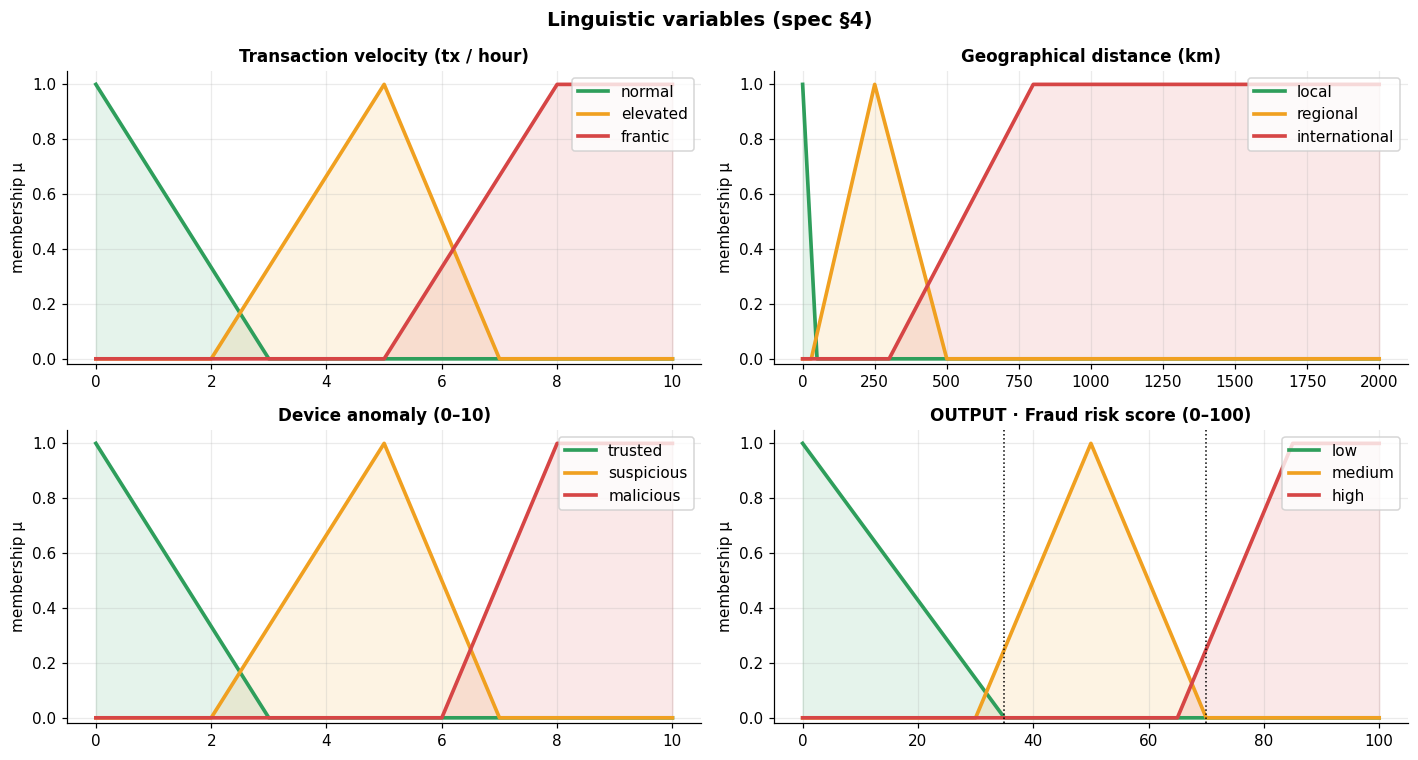

▶ Overseas business traveller (TC-02) – 2 tx/h, 1400 km away, fairly trusted device



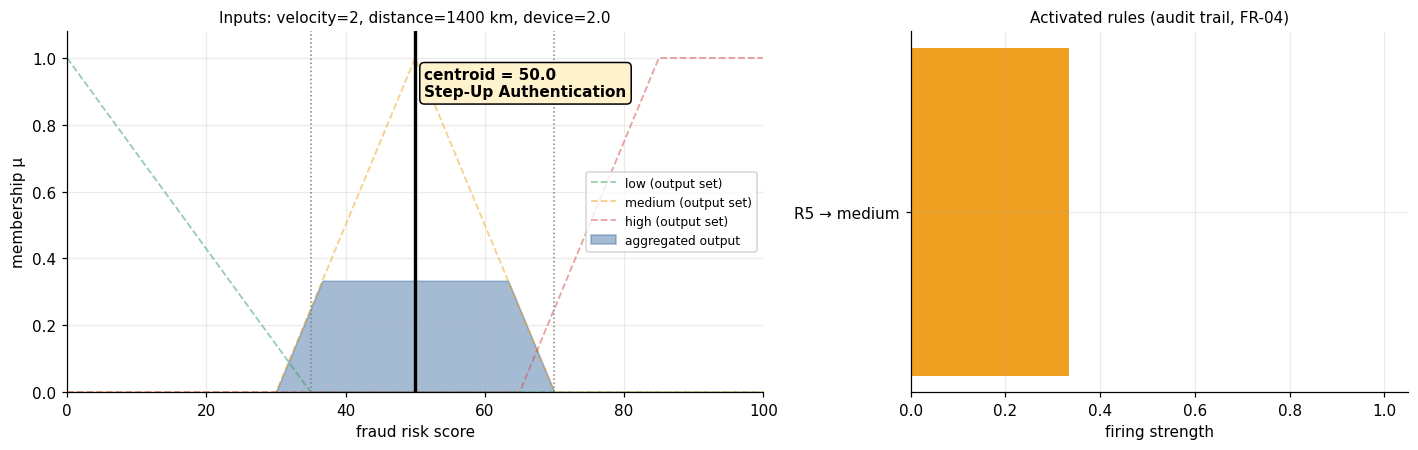

{
  "transaction_id": "TX-14DF561A",
  "account_id": "ACC-DEMO",
  "timestamp": "2026-10-28T13:12:02+00:00",
  "status_code": 202,
  "action": "TRIGGER_OTP_CHALLENGE",
  "decision": "Step-Up Authentication",
  "risk_score": 50.0,
  "risk_band": "MEDIUM",
  "inputs_used": {
    "velocity_1h": 2.0,
    "geo_distance_km": 1400.0,
    "device_anomaly_score": 2.0
  },
  "memberships": {
    "velocity": {
      "normal": 0.3333
    },
    "geo_distance": {
      "international": 1.0
    },
    "device_anomaly": {
      "trusted": 0.3333
    }
  },
  "fired_rules": [
    {
      "rule_id": "R5",
      "rule": "IF velocity=normal AND geo=international AND device=trusted THEN risk=medium",
      "strength": 0.3333,
      "consequent": "medium",
      "origin": "spec"
    }
  ],
  "explanation": "Score 50.0 (MEDIUM). Driven by R5 (medium, strength 0.33)",
  "flags": [],
  "warnings": [],
  "engine": {
    "rule_set": "extended",
    "defuzzification": "centroid",
    "spec_id": "SPEC-BARCLAYS-FR

In [5]:
# ===== SECTION 4 · DEMO =====
plot_memberships()

print("▶ Overseas business traveller (TC-02) – 2 tx/h, 1400 km away, fairly trusted device\n")
r = explain(2, 1400, 2.0)
print(json.dumps(clean(r), indent=2))

## 5 · Acceptance tests (spec §7)

Two engines are verified side by side:

* **Spec-only (R1–R6)** – the blueprint exactly as written.
* **Extended (R1–R10)** – adds labelled rules R7–R10.

> 🔎 **Verification finding:** with only R1–R6, **TC-04 (Emulator Spoofing, velocity 7 / 25 km / device 8) cannot pass** – *no rule fires at all* (velocity 7 is "frantic" at 0.67, but R4 needs a *suspicious* device and R1 needs *international* distance; device 8 is *malicious*, which only R6 handles, and only for *normal* velocity). Rule **R8** (`frantic + malicious → high`) fixes it. R7, R9 and R10 close the remaining holes (quantified in Section 8).

In [6]:
# ===== SECTION 5 · ACCEPTANCE TESTS =====
ACCEPTANCE = [  # id, name, velocity, distance_km, device, (score_lo, score_hi), expected action
    ("TC-01", "Regular Local Shopper",       1,   12, 1.0, (0.0, 25.0),  "Allow Transaction"),
    ("TC-02", "Overseas Business Traveler",  2, 1400, 2.0, (35.1, 65.0), "Step-Up Authentication"),
    ("TC-03", "Credential Stuffing Attack",  9, 1800, 9.0, (75.0, 100.0), "Block & Alert"),
    ("TC-04", "Emulator Spoofing / Local",   7,   25, 8.0, (65.0, 90.0), "Block & Alert"),
]

def run_acceptance(eng):
    rows = []
    for tc, name, v, g, d, (lo, hi), exp in ACCEPTANCE:
        r = eng.evaluate(make_payload(v, g, d, txid=tc))
        sc = r["risk_score"]
        ok_score, ok_act = lo <= sc <= hi, r["decision"] == exp
        rows.append({"Test": tc, "Scenario": name, "Input (v, km, dev)": f"{v}, {g}, {d}",
                     "Expected score": f"{lo}–{hi}", "Score": sc, "Expected action": exp, "Action": r["decision"],
                     "Rules fired": ", ".join(f"{f['rule_id']}:{f['strength']:.2f}" for f in r["fired_rules"]) or "— none —",
                     "Result": "✅ PASS" if ok_score and ok_act else "❌ FAIL"})
    return pd.DataFrame(rows)

acc_spec = run_acceptance(engine_spec)
acc_ext  = run_acceptance(engine)
print("── Spec-only engine (R1–R6, exactly as written) ──");  display(acc_spec)
print("── Extended engine (R1–R10) ──");                       display(acc_ext)
print(f"\nSpec-only: {(acc_spec.Result.str.contains('PASS')).sum()}/4 pass   |   Extended: {(acc_ext.Result.str.contains('PASS')).sum()}/4 pass")
assert (acc_ext.Result.str.contains("PASS")).all(), "extended engine must satisfy all acceptance tests"

── Spec-only engine (R1–R6, exactly as written) ──


,Test,Scenario,"Input (v, km, dev)",Expected score,Score,Expected action,Action,Rules fired,Result
0,TC-01,Regular Local Shopper,"1, 12, 1.0",0.0–25.0,12.61,Allow Transaction,Allow Transaction,R2:0.67,✅ PASS
1,TC-02,Overseas Business Traveler,"2, 1400, 2.0",35.1–65.0,50.00,Step-Up Authentication,Step-Up Authentication,R5:0.33,✅ PASS
2,TC-03,Credential Stuffing Attack,"9, 1800, 9.0",75.0–100.0,86.86,Block & Alert,Block & Alert,R1:1.00,✅ PASS
3,TC-04,Emulator Spoofing / Local,"7, 25, 8.0",65.0–90.0,50.00,Block & Alert,Step-Up Authentication,— none —,❌ FAIL


── Extended engine (R1–R10) ──


,Test,Scenario,"Input (v, km, dev)",Expected score,Score,Expected action,Action,Rules fired,Result
0,TC-01,Regular Local Shopper,"1, 12, 1.0",0.0–25.0,12.61,Allow Transaction,Allow Transaction,R2:0.67,✅ PASS
1,TC-02,Overseas Business Traveler,"2, 1400, 2.0",35.1–65.0,50.00,Step-Up Authentication,Step-Up Authentication,R5:0.33,✅ PASS
2,TC-03,Credential Stuffing Attack,"9, 1800, 9.0",75.0–100.0,86.86,Block & Alert,Block & Alert,"R1:1.00, R8:1.00",✅ PASS
3,TC-04,Emulator Spoofing / Local,"7, 25, 8.0",65.0–90.0,85.60,Block & Alert,Block & Alert,R8:0.67,✅ PASS



Spec-only: 3/4 pass   |   Extended: 4/4 pass


## 6 · Test-input library (great for a live demo)

21 named scenarios covering every action, boundary values, an out-of-range input, and some deliberately *interesting* cases. The `Expected` column is the analyst's expectation; the notebook flags any mismatch, so this doubles as a regression suite.

In [7]:
# ===== SECTION 6 · TEST-INPUT LIBRARY =====
A, S_, B = "Allow Transaction", "Step-Up Authentication", "Block & Alert"
SCENARIOS = [  # name, velocity/h, distance km, device score, expected action
    ("TC-01  Regular local shopper",                       1,   12,   1.0, A),
    ("TC-02  Overseas business traveller",                 2, 1400,   2.0, S_),
    ("TC-03  Credential-stuffing attack",                  9, 1800,   9.0, B),
    ("TC-04  Emulator spoofing, local",                    7,   25,   8.0, B),
    ("Regional commuter (legit)",                          1,  150,   1.0, S_),
    ("Weekend regional trip, power user (legit)",          3,  300,   2.0, S_),
    ("Calm local activity, slightly odd device",           1,   10,   5.0, S_),
    ("Festival shopper – burst of buys, trusted device",   9,    5,   0.5, S_),
    ("Busier-than-usual at home",                          5,   10,   1.0, S_),
    ("Tourist, first day abroad, trusted phone",           0,  900,   0.0, S_),
    ("Account takeover abroad, low velocity",              1, 1500,   9.0, B),
    ("BORDERLINE · frantic + suspicious + regional",       8,  200,   4.0, S_),
    ("Boundary · all zeros",                               0,    0,   0.0, A),
    ("Boundary · worst case (all maxima)",                10, 2000,  10.0, B),
    ("Mid-range everything",                               5,  250,   5.0, S_),
    ("Card testing abroad on a trusted device",            9, 1000,   1.0, S_),
    ("Out-of-range input (gets clamped + flagged)",       15, 3500,  12.0, B),
    ("Local, slightly odd device",                         2,   20,   4.0, S_),
    ("Local, frantic, suspicious device",                  6,   20,   4.0, S_),
    ("⚠ Malicious device, moderate velocity, local",       5,   30,   7.0, S_),
    ("Near-zero risk, device a bit off",                   0,    0,   2.5, A),
]

def run_scenarios(scenarios, eng):
    rows = []
    for name, v, g, d, exp in scenarios:
        r = eng.evaluate(make_payload(v, g, d))
        rows.append({"Scenario": name, "Velocity/h": v, "Dist km": g, "Device": d, "Score": r["risk_score"],
                     "Action": r["decision"], "HTTP": r["status_code"],
                     "Rules fired": ", ".join(f"{f['rule_id']}:{f['strength']:.2f}" for f in r["fired_rules"]),
                     "Flags": ", ".join(r["flags"]), "Expected": exp, "Match": "✔" if r["decision"] == exp else "✖"})
    return pd.DataFrame(rows)

lib = run_scenarios(SCENARIOS, engine)
show(lib.drop(columns=["Expected"]))
print(f"\nMatches analyst expectation: {(lib.Match == '✔').sum()}/{len(lib)}")
print("Action mix:", lib.Action.value_counts().to_dict())

,Scenario,Velocity/h,Dist km,Device,Score,Action,HTTP,Rules fired,Flags,Match
0,TC-01 Regular local shopper,1,12,1.000000,12.610000,Allow Transaction,200,R2:0.67,,✔
1,TC-02 Overseas business traveller,2,1400,2.000000,50.000000,Step-Up Authentication,202,R5:0.33,,✔
2,TC-03 Credential-stuffing attack,9,1800,9.000000,86.860000,Block & Alert,403,"R1:1.00, R8:1.00",EXTENSION_RULES_USED:R8,✔
3,"TC-04 Emulator spoofing, local",7,25,8.000000,85.600000,Block & Alert,403,R8:0.67,EXTENSION_RULES_USED:R8,✔
4,Regional commuter (legit),1,150,1.000000,50.000000,Step-Up Authentication,202,R3:0.55,,✔
5,"Weekend regional trip, power user (legit)",3,300,2.000000,50.000000,Step-Up Authentication,202,R3:0.80,,✔
6,"Calm local activity, slightly odd device",1,10,5.000000,50.000000,Step-Up Authentication,202,R9:0.67,EXTENSION_RULES_USED:R9,✔
7,"Festival shopper – burst of buys, trusted device",9,5,0.500000,50.000000,Step-Up Authentication,202,R10:0.83,EXTENSION_RULES_USED:R10,✔
8,Busier-than-usual at home,5,10,1.000000,50.000000,Step-Up Authentication,202,R3:1.00,,✔
9,"Tourist, first day abroad, trusted phone",0,900,0.000000,50.000000,Step-Up Authentication,202,R5:1.00,,✔



Matches analyst expectation: 21/21
Action mix: {'Step-Up Authentication': 13, 'Block & Alert': 5, 'Allow Transaction': 3}


## 7 · Test it manually

Three ways, from quickest to most "API-like":

1. **Sliders** (live chart + decision) – best for a demo.
2. **Type your own numbers** – edit one cell and run it.
3. **Paste your own JSON payload** – exactly what the API contract in spec §4.A would receive.

In [8]:
# ===== SECTION 7a · INTERACTIVE SLIDERS =====
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
    HAVE_WIDGETS = True
except ImportError:
    HAVE_WIDGETS = False
    print("ipywidgets not installed – use 7b / 7c below (or `pip install ipywidgets`).")

if HAVE_WIDGETS:
    _st = {"description_width": "130px"}; _ly = widgets.Layout(width="560px")
    w_v = widgets.IntSlider(value=2, min=0, max=10, step=1, description="Velocity (tx/h)", style=_st, layout=_ly, continuous_update=False)
    w_g = widgets.FloatSlider(value=1400, min=0, max=2000, step=10, description="Distance (km)", style=_st, layout=_ly, continuous_update=False)
    w_d = widgets.FloatSlider(value=2.0, min=0, max=10, step=0.1, description="Device anomaly", style=_st, layout=_ly, continuous_update=False)
    w_x = widgets.Checkbox(value=True, description="Use extended rules R7–R10 (untick = spec-only R1–R6)", indent=False, layout=widgets.Layout(width="560px"))
    def _live(v, g, d, ext):
        r = explain(v, g, d, eng=engine if ext else engine_spec)
        print(f"{r['decision']}  |  HTTP {r['status_code']}  |  {r['action']}  |  score {r['risk_score']}  |  flags: {r['flags'] or '—'}")
    display(widgets.VBox([w_v, w_g, w_d, w_x]),
            widgets.interactive_output(_live, {"v": w_v, "g": w_g, "d": w_d, "ext": w_x}))

Output()

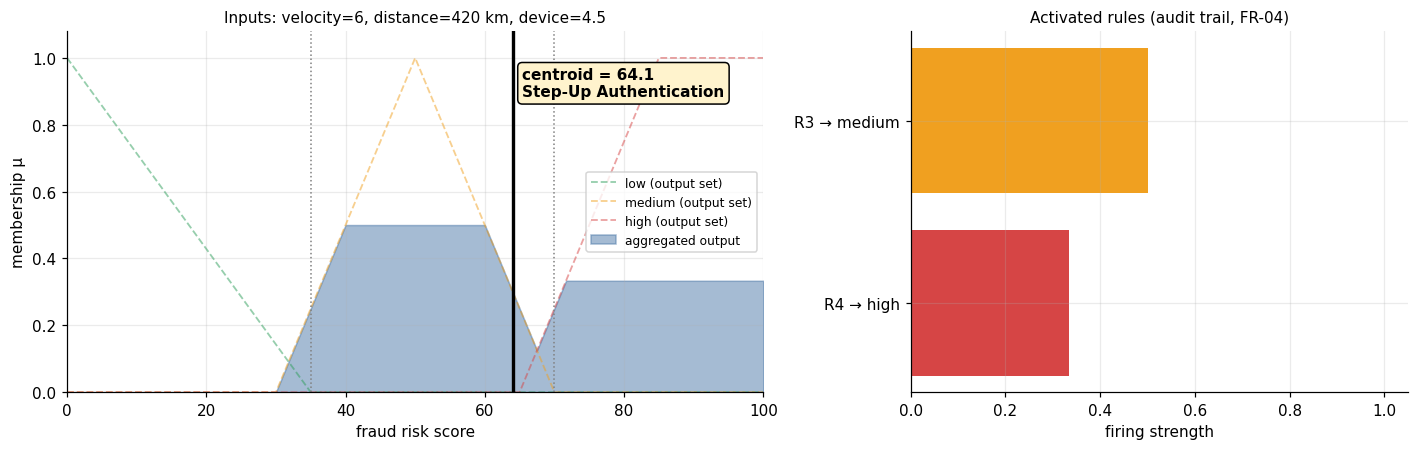

Score 64.1 (MEDIUM). Driven by R3 (medium, strength 0.50), R4 (high, strength 0.33)


In [9]:
# ===== SECTION 7b · TYPE YOUR OWN NUMBERS  (edit, then Shift+Enter) =====
VELOCITY_PER_HOUR = 6      # integer 0–10
DISTANCE_KM       = 420    # 0–2000
DEVICE_ANOMALY    = 4.5    # 0.0–10.0
USE_EXTENDED      = True   # False -> spec-only R1–R6

r = explain(VELOCITY_PER_HOUR, DISTANCE_KM, DEVICE_ANOMALY, eng=engine if USE_EXTENDED else engine_spec)
print(r["explanation"])

In [10]:
# ===== SECTION 7c · PASTE YOUR OWN JSON PAYLOAD  (spec §4.A contract) =====
MY_PAYLOAD = {
    "transaction_id": "TX-DEMO-001",
    "account_id": "ACC-12345",
    "timestamp": "2026-10-13T14:32:00Z",
    "amount_gbp": 249.99,
    "metrics": {"velocity_1h": 8, "geo_distance_km": 640.0, "device_anomaly_score": 6.5}
}
resp = engine.evaluate(MY_PAYLOAD)
print(json.dumps(resp, indent=2))

{
  "transaction_id": "TX-DEMO-001",
  "account_id": "ACC-12345",
  "timestamp": "2026-10-13T14:32:00Z",
  "status_code": 403,
  "action": "FREEZE_SESSION_NOTIFY_OPS",
  "decision": "Block & Alert",
  "risk_score": 83.74,
  "risk_band": "HIGH",
  "inputs_used": {
    "velocity_1h": 8.0,
    "geo_distance_km": 640.0,
    "device_anomaly_score": 6.5
  },
  "memberships": {
    "velocity": {
      "frantic": 1.0
    },
    "geo_distance": {
      "international": 0.68
    },
    "device_anomaly": {
      "suspicious": 0.25,
      "malicious": 0.25
    }
  },
  "fired_rules": [
    {
      "rule_id": "R1",
      "rule": "IF velocity=frantic AND geo=international AND device=malicious THEN risk=high",
      "strength": 0.25,
      "consequent": "high",
      "origin": "spec"
    },
    {
      "rule_id": "R4",
      "rule": "IF velocity=frantic AND device=suspicious THEN risk=high",
      "strength": 0.25,
      "consequent": "high",
      "origin": "spec"
    },
    {
      "rule_id": "R8",

## 8 · Risk surface & rule-coverage analysis

* **Heatmaps** – how the score responds to velocity × distance for a trusted, a suspicious and a malicious device. The black lines are the 35 / 70 decision thresholds. Smooth gradients (instead of cliffs) are the point of using fuzzy logic.
* **Coverage** – sweeps 18 081 grid points and counts inputs where *no rule fires*. This is the quantitative evidence behind the extended rule set.

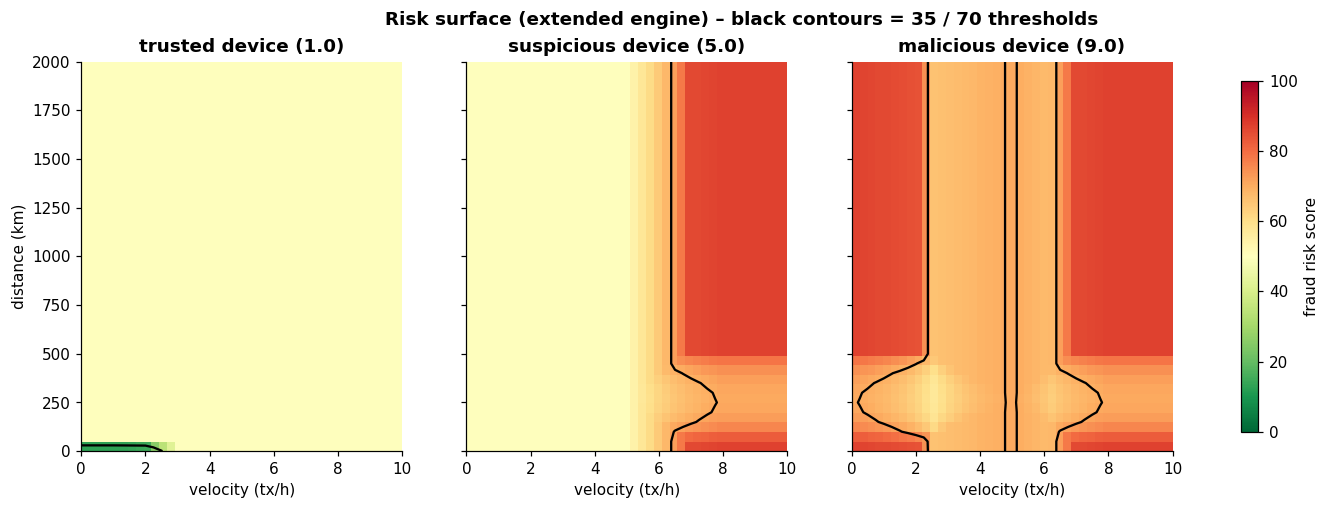

Grid points tested: 18,081
  Spec-only (R1–R6)    -> inputs with NO rule firing:  2,289  ( 12.7%)
  Extended (R1–R10)    -> inputs with NO rule firing:      0  (  0.0%)


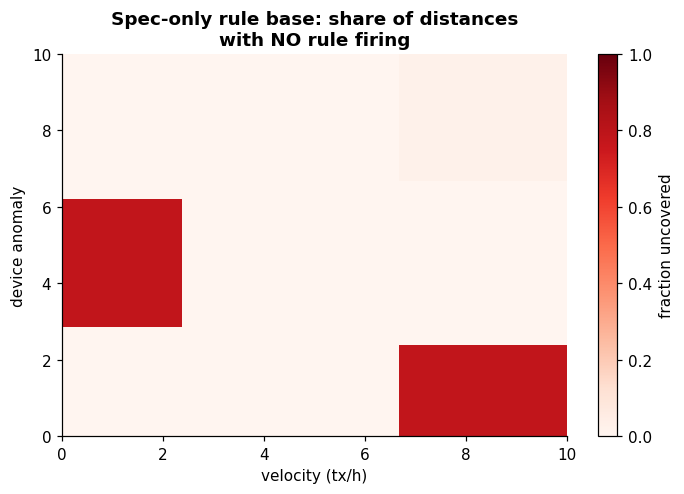

Examples of inputs the 6-rule spec cannot score:


,velocity,distance_km,device
0,0.0,1300.0,3.5
1,0.0,700.0,5.5
2,1.0,850.0,5.0
3,1.5,600.0,3.0
4,7.0,800.0,0.5
5,8.0,850.0,1.5
6,8.5,650.0,1.0
7,8.5,1800.0,2.0


In [11]:
# ===== SECTION 8 · HEATMAPS + COVERAGE =====
gv, gg = np.linspace(0, 10, 41), np.linspace(0, 2000, 41)
GV, GG = np.meshgrid(gv, gg)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, dev, label in zip(axes, (1.0, 5.0, 9.0), ("trusted device (1.0)", "suspicious device (5.0)", "malicious device (9.0)")):
    sc = engine.infer_batch(GV.ravel(), GG.ravel(), np.full(GV.size, dev))["score"].reshape(GV.shape)
    im = ax.imshow(sc, origin="lower", aspect="auto", extent=[0, 10, 0, 2000], cmap="RdYlGn_r", vmin=0, vmax=100)
    ax.contour(GV, GG, sc, levels=[35, 70], colors="k", linewidths=1.5)
    ax.set_title(label, weight="bold"); ax.set_xlabel("velocity (tx/h)"); ax.grid(False)
axes[0].set_ylabel("distance (km)")
fig.colorbar(im, ax=axes, label="fraud risk score", shrink=0.9)
plt.suptitle("Risk surface (extended engine) – black contours = 35 / 70 thresholds", weight="bold"); plt.show()

# ---- coverage: where does NO rule fire? ----
cv, cg, cd = np.linspace(0, 10, 21), np.linspace(0, 2000, 41), np.linspace(0, 10, 21)
V, G, D = (a.ravel() for a in np.meshgrid(cv, cg, cd, indexing="ij"))
cov = {}
for name, eng in (("Spec-only (R1–R6)", engine_spec), ("Extended (R1–R10)", engine)):
    cov[name] = eng.infer_batch(V, G, D)["no_rule"]
print(f"Grid points tested: {len(V):,}")
for k, m in cov.items():
    print(f"  {k:20} -> inputs with NO rule firing: {m.sum():>6,}  ({100*m.mean():5.1f}%)")

unc = cov["Spec-only (R1–R6)"].reshape(len(cv), len(cg), len(cd)).mean(axis=1)   # (velocity, device)
fig, ax = plt.subplots(figsize=(6.5, 4.6))
im = ax.imshow(unc.T, origin="lower", aspect="auto", extent=[0, 10, 0, 10], cmap="Reds", vmin=0, vmax=1)
ax.set_xlabel("velocity (tx/h)"); ax.set_ylabel("device anomaly"); ax.grid(False)
ax.set_title("Spec-only rule base: share of distances\nwith NO rule firing", weight="bold")
fig.colorbar(im, label="fraction uncovered"); plt.tight_layout(); plt.show()

ex = pd.DataFrame({"velocity": V, "distance_km": G, "device": D})[cov["Spec-only (R1–R6)"]].sample(8, random_state=1).sort_values(["velocity", "device"])
print("Examples of inputs the 6-rule spec cannot score:"); display(ex.reset_index(drop=True))

## 9 · Robustness & performance

* **Bad payloads** must be rejected (never silently authorised) with a clear message.
* **Fuzzing** – 20 000 random in-range inputs must always yield a finite score in [0, 100].
* **Latency** – FR-01 says ≤ 50 ms end-to-end, NFR-01 says ≤ 30 ms for inference. (Colab CPU timings; a production service would be separately load-tested.)

In [12]:
# ===== SECTION 9 · ROBUSTNESS + PERFORMANCE =====
good = make_payload(3, 100, 2)
def mutate(**kw):
    p = json.loads(json.dumps(good));
    for k, v in kw.items():
        if k.startswith("m_"): p["metrics"][k[2:]] = v
        else: p[k] = v
    return p
def drop(path):
    p = json.loads(json.dumps(good))
    if "." in path: a, b = path.split("."); del p[a][b]
    else: del p[path]
    return p

bad_cases = {
    "missing metrics.velocity_1h":  drop("metrics.velocity_1h"),
    "missing transaction_id":       drop("transaction_id"),
    "velocity as string":           mutate(m_velocity_1h="fast"),
    "device = NaN":                 mutate(m_device_anomaly_score=float("nan")),
    "distance = +inf":              mutate(m_geo_distance_km=float("inf")),
    "negative amount":              mutate(amount_gbp=-5),
    "bad timestamp":                mutate(timestamp="yesterday"),
    "boolean as number":            mutate(m_velocity_1h=True),
    "payload is a list":            [1, 2, 3],
}
rows = [{"Case": k, "HTTP": (r := engine.evaluate(p))["status_code"], "Action": r["action"], "Reason": "; ".join(r.get("errors", []))[:70]}
        for k, p in bad_cases.items()]
rows += [{"Case": "out-of-range (clamped)", "HTTP": (r := engine.evaluate(mutate(m_velocity_1h=99, m_geo_distance_km=-40)))["status_code"],
          "Action": r["action"], "Reason": "; ".join(r["warnings"])[:70]}]
bad_df = pd.DataFrame(rows); display(bad_df)
assert all(bad_df.HTTP[:-1] == 400), "invalid payloads must be rejected"

# ---- fuzz ----
rng = np.random.default_rng(7)
N = 20_000
fz = engine.infer_batch(rng.uniform(0, 10, N), rng.uniform(0, 2000, N), rng.uniform(0, 10, N))
fuzz_ok = bool(np.isfinite(fz["score"]).all() and fz["score"].min() >= 0 and fz["score"].max() <= 100)
print(f"\nFuzz {N:,} inputs: score range [{fz['score'].min():.1f}, {fz['score'].max():.1f}], all finite & in [0,100]: {fuzz_ok}")

# ---- latency ----
for _ in range(50): engine.evaluate(make_payload(2, 300, 3))            # warm-up
pls = [make_payload(*t) for t in zip(rng.integers(0, 11, 500), rng.uniform(0, 2000, 500), rng.uniform(0, 10, 500))]
res = [engine.evaluate(p) for p in pls]
e2e = np.array([r["latency_ms"] for r in res]); inf = np.array([r["inference_ms"] for r in res])
t0 = time.perf_counter(); engine.infer_batch(*(rng.uniform(0, m, 10_000) for m in (10, 2000, 10))); batch_s = time.perf_counter() - t0
lat = pd.DataFrame({"mean ms": [e2e.mean(), inf.mean()], "p95 ms": [np.percentile(e2e, 95), np.percentile(inf, 95)],
                    "p99 ms": [np.percentile(e2e, 99), np.percentile(inf, 99)], "max ms": [e2e.max(), inf.max()],
                    "budget ms": [50, 30]}, index=["end-to-end (FR-01)", "inference only (NFR-01)"]).round(3)
display(lat)
print(f"Batch throughput: 10,000 transactions in {batch_s*1000:.0f} ms  (~{10_000/batch_s:,.0f} tx/s)")
lat_ok = bool(e2e.max() < 50 and inf.max() < 30)
print("Latency budgets met (max < budget):", lat_ok)

,Case,HTTP,Action,Reason
0,missing metrics.velocity_1h,400,REJECT_INVALID_PAYLOAD,metrics.velocity_1h must be a finite number
1,missing transaction_id,400,REJECT_INVALID_PAYLOAD,'transaction_id' must be a non-empty string
2,velocity as string,400,REJECT_INVALID_PAYLOAD,metrics.velocity_1h must be a finite number
3,device = NaN,400,REJECT_INVALID_PAYLOAD,metrics.device_anomaly_score must be a finite number
4,distance = +inf,400,REJECT_INVALID_PAYLOAD,metrics.geo_distance_km must be a finite number
5,negative amount,400,REJECT_INVALID_PAYLOAD,'amount_gbp' must be a finite number >= 0
6,bad timestamp,400,REJECT_INVALID_PAYLOAD,'timestamp' must be ISO-8601
7,boolean as number,400,REJECT_INVALID_PAYLOAD,metrics.velocity_1h must be a finite number
8,payload is a list,400,REJECT_INVALID_PAYLOAD,payload must be a JSON object
9,out-of-range (clamped),202,TRIGGER_OTP_CHALLENGE,"metrics.velocity_1h=99 outside [0,10] -> clamped; metrics.geo_dist..."



Fuzz 20,000 inputs: score range [12.5, 86.9], all finite & in [0,100]: True


,mean ms,p95 ms,p99 ms,max ms,budget ms
end-to-end (FR-01),0.384,0.547,0.637,1.095,50
inference only (NFR-01),0.295,0.423,0.502,0.983,30


Batch throughput: 10,000 transactions in 183 ms  (~54,748 tx/s)
Latency budgets met (max < budget): True


## 10 · NFR-02 – false positives for legitimate regional travellers

NFR-02 asks for ≥ 20 % fewer false-positive **blocks** than a legacy binary-threshold engine. The blueprint does not define that legacy engine or provide data, so this is an **illustrative simulation**, with clearly stated assumptions you can edit:

* **Legacy engine (assumed):** block if distance > 100 km **or** velocity > 4 **or** device score > 5; otherwise allow.
* **Legit regional travellers (synthetic):** 30–500 km away, Poisson(1.5) tx/h, device ≈ N(1.5, 1).
* **Fraud (synthetic):** three archetypes – credential stuffing, emulator spoofing, account takeover abroad.

⚠ This shows the *mechanism* (overlapping sets turn cliff-edge blocks into graded step-ups). It is **not** evidence about real Barclays traffic; proving NFR-02 needs production-like labelled data. Step-up OTPs are still friction, so that is reported too.

,Legacy binary (%),Fuzzy (FIS) (%)
Legit travellers BLOCKED (false-positive blocks),85.6,0.0
Legit travellers blocked or OTP-challenged (friction),85.6,97.4
Fraud BLOCKED,100.0,66.1
Fraud blocked or OTP-challenged,100.0,100.0



False-positive BLOCK reduction vs legacy: 100.0%   (target ≥ 20%)  ->  ✅ met on this simulation


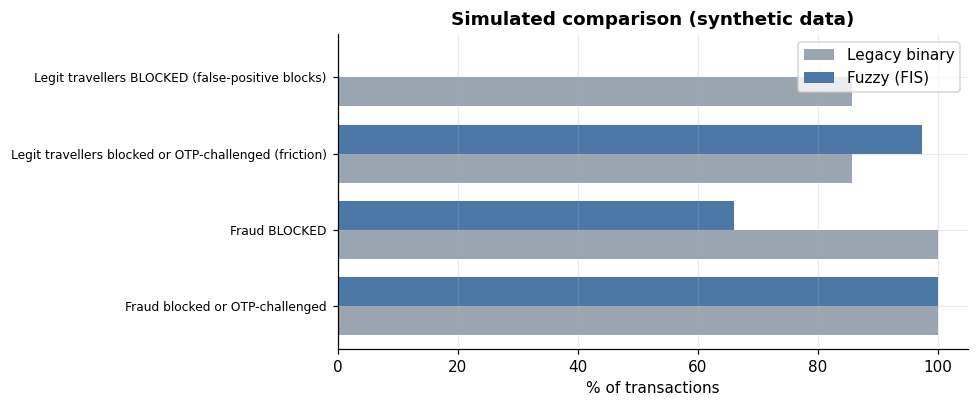

In [13]:
# ===== SECTION 10 · NFR-02 SIMULATION =====
LEGACY = {"max_geo_km": 100, "max_velocity": 4, "max_device": 5}      # <- edit to test other assumptions
def legacy_block(v, g, d):
    return (g > LEGACY["max_geo_km"]) | (v > LEGACY["max_velocity"]) | (d > LEGACY["max_device"])

rng = np.random.default_rng(42)
nL, nF = 5000, 3000
L = (np.clip(rng.poisson(1.5, nL), 0, 10), rng.uniform(30, 500, nL), np.clip(rng.normal(1.5, 1.0, nL), 0, 10))
k = nF // 3
F = (np.concatenate([rng.integers(7, 11, k), rng.integers(5, 10, k), rng.integers(1, 5, k)]),
     np.concatenate([rng.uniform(800, 2000, k), rng.uniform(0, 100, k), rng.uniform(500, 2000, k)]),
     np.concatenate([rng.uniform(7, 10, k), rng.uniform(6, 10, k), rng.uniform(5, 9, k)]))

def summarise(v, g, d):
    act = batch_decisions(engine.infer_batch(v, g, d)["score"])
    return {"leg_block": legacy_block(v, g, d).mean() * 100, "fis_block": (act == "Block & Alert").mean() * 100,
            "fis_stepup": (act == "Step-Up Authentication").mean() * 100}
sl, sf = summarise(*L), summarise(*F)

reduction = (sl["leg_block"] - sl["fis_block"]) / sl["leg_block"] * 100
tbl = pd.DataFrame({
    "Legacy binary": [sl["leg_block"], sl["leg_block"], sf["leg_block"], sf["leg_block"]],
    "Fuzzy (FIS)":   [sl["fis_block"], sl["fis_block"] + sl["fis_stepup"], sf["fis_block"], sf["fis_block"] + sf["fis_stepup"]]},
    index=["Legit travellers BLOCKED (false-positive blocks)", "Legit travellers blocked or OTP-challenged (friction)",
           "Fraud BLOCKED", "Fraud blocked or OTP-challenged"]).round(1)
display(tbl.rename(columns=lambda c: c + " (%)"))
print(f"\nFalse-positive BLOCK reduction vs legacy: {reduction:.1f}%   (target ≥ 20%)  ->  {'✅ met' if reduction >= 20 else '❌ not met'} on this simulation")
nfr02_ok = reduction >= 20

fig, ax = plt.subplots(figsize=(9, 3.8)); x = np.arange(len(tbl)); w = 0.38
ax.barh(x + w/2, tbl["Legacy binary"], w, label="Legacy binary", color="#9aa5b1")
ax.barh(x - w/2, tbl["Fuzzy (FIS)"], w, label="Fuzzy (FIS)", color="#4c78a8")
ax.set_yticks(x); ax.set_yticklabels(tbl.index, fontsize=8); ax.invert_yaxis(); ax.set_xlabel("% of transactions")
ax.legend(); ax.set_title("Simulated comparison (synthetic data)", weight="bold"); plt.tight_layout(); plt.show()

## 11 · Audit export & compliance scorecard

Every decision carries its activated rules and degrees (FR-04). Here the whole scenario library is exported as JSON for Fraud Operations (NFR-03), then the spec's requirements are checked automatically from the results above.

In [14]:
# ===== SECTION 11 · AUDIT EXPORT + SCORECARD =====
audit = [clean(engine.evaluate(make_payload(v, g, d, txid=f"AUD-{i:03d}"))) for i, (n, v, g, d, _) in enumerate(SCENARIOS, 1)]
with open("audit_log.json", "w") as fh:
    json.dump(audit, fh, indent=2)
with open("audit_log.jsonl", "w") as fh:
    fh.write("\n".join(json.dumps(a) for a in audit))
reloaded = json.load(open("audit_log.json"))
print(f"Wrote audit_log.json + audit_log.jsonl ({len(audit)} decisions); round-trip OK: {len(reloaded) == len(audit)}")
print("\nSample audit record:"); print(json.dumps(audit[3], indent=2)[:1500], "...")
# In Colab, uncomment to download:
# from google.colab import files; files.download("audit_log.json")

ok = lambda b: "✅ PASS" if b else "❌ FAIL"
scores_ok = all(0 <= a["risk_score"] <= 100 for a in audit)
actions_seen = {a["decision"] for a in audit}
card = pd.DataFrame([
    ("FR-01", "Score 0–100 within 50 ms",                         ok(scores_ok and fuzz_ok and e2e.max() < 50)),
    ("FR-02", "Linguistic variables, overlapping sets (no crisp thresholds)", ok(True)),
    ("FR-03", "All three actions reachable (Allow / Step-Up / Block)", ok(actions_seen == {A, S_, B})),
    ("FR-04", "Fired rules logged for every decision",            ok(all(a["fired_rules"] or "NO_RULE_FIRED_FALLBACK" in a["flags"] for a in audit))),
    ("NFR-01", "Inference ≤ 30 ms",                               ok(inf.max() < 30)),
    ("NFR-02", "≥ 20% fewer false-positive blocks (simulation, assumed baseline)", ok(nfr02_ok)),
    ("NFR-03", "Rule firings + degrees exportable as JSON",       ok(len(reloaded) == len(audit))),
    ("TC-01…04", "Acceptance tests – extended engine",            ok((acc_ext.Result.str.contains('PASS')).all())),
    ("TC-01…04", "Acceptance tests – spec-only R1–R6 (see finding)", ok((acc_spec.Result.str.contains('PASS')).all())),
], columns=["Requirement", "Check", "Status"])
display(card)

Wrote audit_log.json + audit_log.jsonl (21 decisions); round-trip OK: True

Sample audit record:
{
  "transaction_id": "AUD-004",
  "account_id": "ACC-DEMO",
  "timestamp": "2026-10-28T13:12:25+00:00",
  "status_code": 403,
  "action": "FREEZE_SESSION_NOTIFY_OPS",
  "decision": "Block & Alert",
  "risk_score": 85.6,
  "risk_band": "HIGH",
  "inputs_used": {
    "velocity_1h": 7.0,
    "geo_distance_km": 25.0,
    "device_anomaly_score": 8.0
  },
  "memberships": {
    "velocity": {
      "frantic": 0.6667
    },
    "geo_distance": {
      "local": 0.5
    },
    "device_anomaly": {
      "malicious": 1.0
    }
  },
  "fired_rules": [
    {
      "rule_id": "R8",
      "rule": "IF velocity=frantic AND device=malicious THEN risk=high",
      "strength": 0.6667,
      "consequent": "high",
      "origin": "extension"
    }
  ],
  "explanation": "Score 85.6 (HIGH). Driven by R8 (high, strength 0.67)",
  "flags": [
    "EXTENSION_RULES_USED:R8"
  ],
  "warnings": [],
  "engine": {
    "rul

,Requirement,Check,Status
0,FR-01,Score 0–100 within 50 ms,✅ PASS
1,FR-02,"Linguistic variables, overlapping sets (no crisp thresholds)",✅ PASS
2,FR-03,All three actions reachable (Allow / Step-Up / Block),✅ PASS
3,FR-04,Fired rules logged for every decision,✅ PASS
4,NFR-01,Inference ≤ 30 ms,✅ PASS
5,NFR-02,"≥ 20% fewer false-positive blocks (simulation, assumed baseline)",✅ PASS
6,NFR-03,Rule firings + degrees exportable as JSON,✅ PASS
7,TC-01…04,Acceptance tests – extended engine,✅ PASS
8,TC-01…04,Acceptance tests – spec-only R1–R6 (see finding),❌ FAIL
